# Visualize spatial programs and tissue neighborhoods

Follow cell identity from a guided program to its aligned pathway and
associated genes in mouse spinal cord MERFISH. Then compare spatial
neighborhoods derived from curated and predicted cell identities.

## 1. Load the spatial example

The three examples connect astrocyte, oligodendrocyte and endothelial identities to their guided elements. All cell-level tables are joined by cell ID.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "tutorials/data").is_dir())
sys.path.insert(0, str(ROOT / "tutorials"))
from _common import (configure_plots, save_figure, clean_map, pretty,
                     expression_cmap, program_cmap, pathway_cmap, dot_atlas)

configure_plots()
DATA = ROOT / "tutorials/data"
OUTPUT = ROOT / "tutorials/outputs"

In [2]:
cells = pd.read_csv(DATA / "merfish_cells.csv.gz", dtype={"cell_id": str})
activity = pd.read_csv(DATA / "merfish_program_cells.csv.gz", dtype={"cell_id": str})
programs = pd.read_csv(DATA / "merfish_programs.csv")
cells = cells.merge(activity, on="cell_id", validate="one_to_one")
assert len(cells) == 6602
display(programs[["cell_type", "feature_id", "pathway_label", "marker", "candidate"]])

,cell_type,feature_id,pathway_label,marker,candidate
0,astrocyte-1,82,Amino acid transport across the plasma membrane,Slc7a10,Hrh1
1,oligodendrocyte-2,419,Endogenous sterols,Sema4d,Prox1
2,endothelial,1453,VEGF signaling,Flt1,Ramp2


## 2. Map identity, program, pathway and gene together

Each row shows the same tissue coordinates. Change `GENE_KIND` to
`"candidate"` to display the associated candidates instead of known
markers. Continuous panels use individual robust color ranges; low
values remain visible in pale gray.

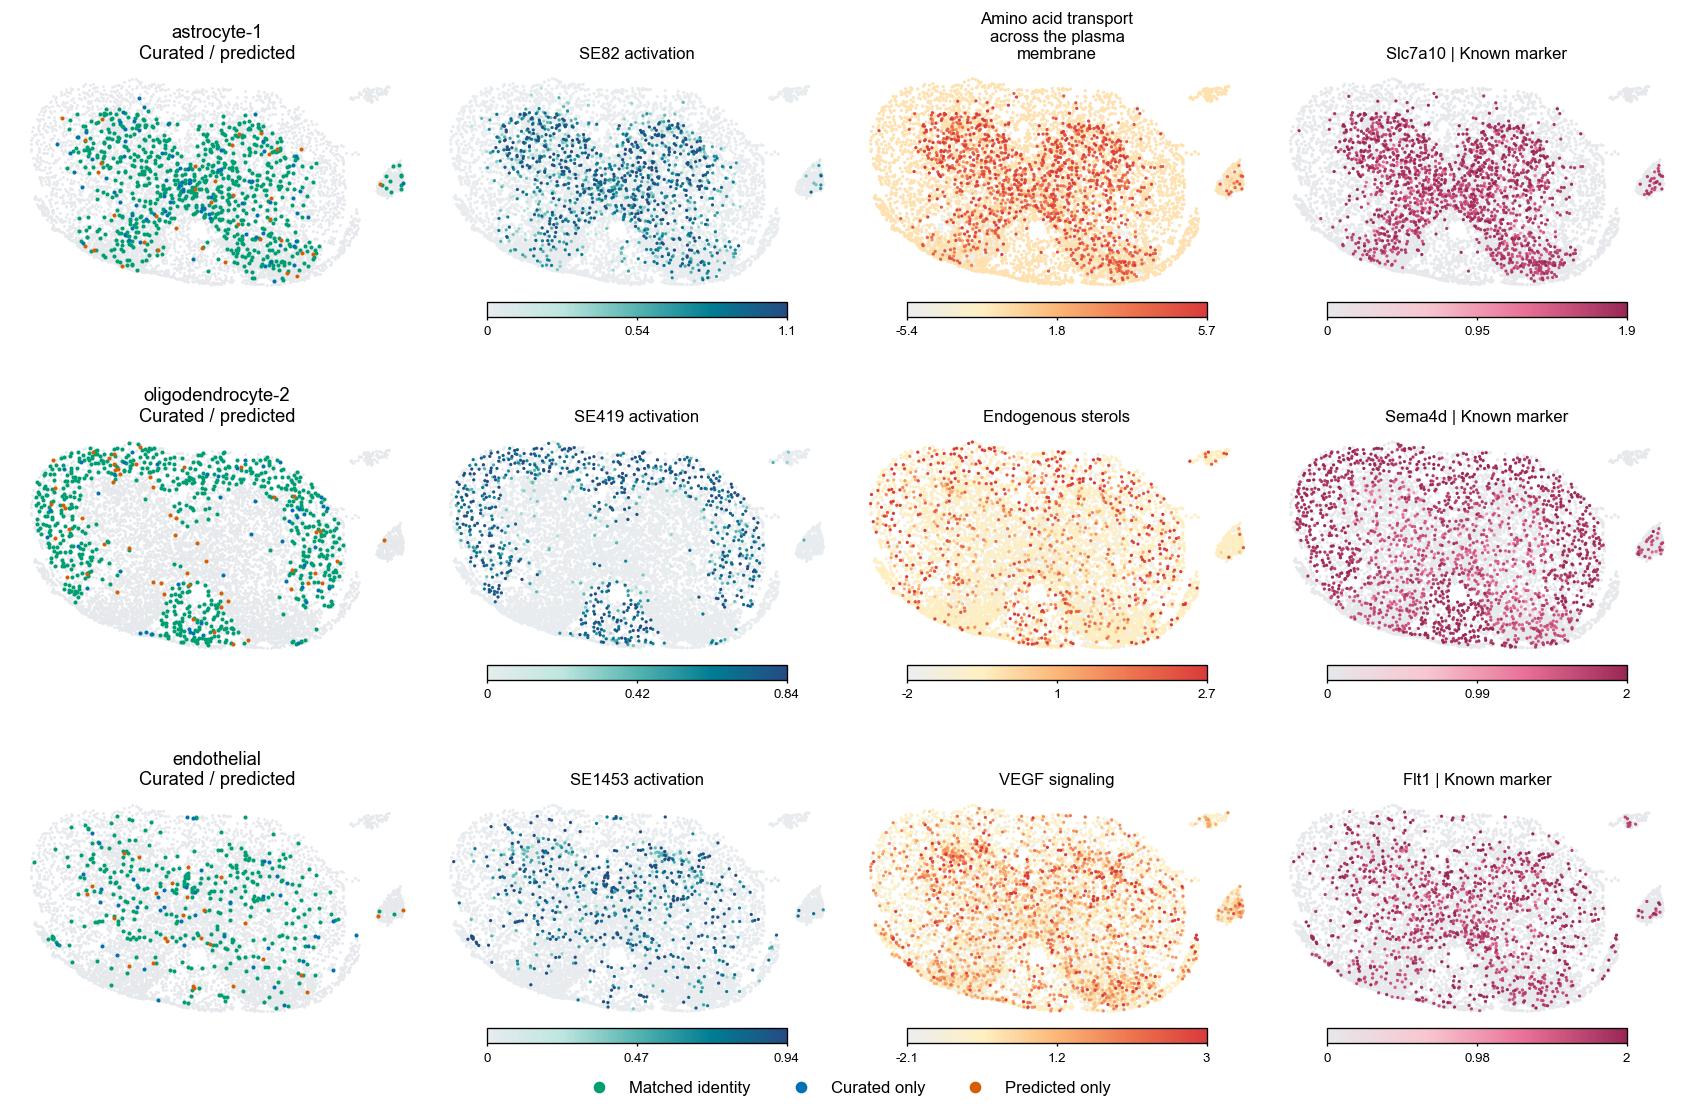

In [3]:
import textwrap
from matplotlib.colors import Normalize, PowerNorm
from matplotlib.lines import Line2D

GENE_KIND = "marker"
identity_colors = {"Matched identity": "#009E73", "Curated only": "#0072B2", "Predicted only": "#D55E00"}
fig, axes = plt.subplots(len(programs), 4, figsize=(14, 9.4), layout="constrained")
for row, item in enumerate(programs.itertuples()):
    curated = cells.annotated_cell_type.eq(item.cell_type)
    predicted = cells.predicted_cell_type.eq(item.cell_type)
    masks = {"Matched identity": curated & predicted,
             "Curated only": curated & ~predicted, "Predicted only": predicted & ~curated}
    ax = axes[row, 0]
    ax.scatter(cells.spatial_x, cells.spatial_y, s=3, color="#e6e9ec", linewidths=0)
    for label, mask in masks.items():
        ax.scatter(cells.loc[mask, "spatial_x"], cells.loc[mask, "spatial_y"],
                   s=6, color=identity_colors[label], linewidths=0)
    ax.set_title(f"{item.cell_type}\nCurated / predicted", fontsize=11)
    clean_map(ax)
    # Reserve the same colorbar space as the three continuous panels.
    spacer = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, 1)), ax=ax,
                          orientation="horizontal", fraction=0.05, pad=0.02, shrink=0.73)
    spacer.solids.set_visible(False)
    spacer.ax.set_axis_off()
    gene = getattr(item, GENE_KIND)
    columns = [f"SE{item.feature_id}", f"pathway_SE{item.feature_id}", gene]
    titles = [f"SE{item.feature_id} activation", textwrap.fill(item.pathway_label, 25),
              f"{gene} | {'Known marker' if GENE_KIND == 'marker' else 'Candidate'}"]
    for col, column, title, cmap in zip(range(1, 4), columns, titles,
                                      [program_cmap(), pathway_cmap(), expression_cmap()]):
        ax = axes[row, col]
        values = cells[column].to_numpy()
        lower = float(np.quantile(values, 0.02)) if col == 2 else 0.0
        upper = max(float(np.quantile(values, 0.98)), lower + 1e-6)
        norm = PowerNorm(1.6, vmin=lower, vmax=upper, clip=True) if col == 2 else Normalize(lower, upper)
        order = np.argsort(values)
        image = ax.scatter(cells.spatial_x.to_numpy()[order], cells.spatial_y.to_numpy()[order],
                           c=values[order], s=3.8, cmap=cmap, norm=norm, linewidths=0)
        ax.set_title(title, fontsize=10)
        clean_map(ax)
        colorbar = fig.colorbar(image, ax=ax, orientation="horizontal", fraction=0.05, pad=0.02, shrink=0.73)
        ticks = norm.inverse(np.linspace(0, 1, 3))
        colorbar.set_ticks(ticks)
        colorbar.set_ticklabels([f"{value:.2g}" for value in ticks])
        colorbar.ax.tick_params(labelsize=8, length=2)
handles = [Line2D([], [], marker="o", linestyle="", color=color, label=label, markersize=6)
           for label, color in identity_colors.items()]
fig.legend(handles=handles, loc="outside lower center", ncol=3, fontsize=10)
save_figure(fig, OUTPUT, "merfish_spatial_program_colocalization")
plt.show()

Program and gene colors span zero to the 98th percentile. Pathway
colors span the 2nd to 98th percentiles, with a power transform to
emphasize high activity. Ranges are panel-specific, so compare spatial
localization rather than absolute color intensity between panels.

## 3. Compute spatial neighborhood enrichment

Connect each cell to its eight nearest spatial neighbors. Enrichment
is the log2 observed-to-expected edge count under independent mixing,
with a pseudocount of one. Expected counts use all edges and the
whole-section cell-type frequencies. This is a descriptive score, not a P value.

In [4]:
from sklearn.neighbors import NearestNeighbors

K = 8
coordinates = cells[["spatial_x", "spatial_y"]].to_numpy()
candidates = NearestNeighbors(n_neighbors=K + 1).fit(coordinates).kneighbors(coordinates, return_distance=False)
neighbors = np.array([row[row != i][:K] for i, row in enumerate(candidates)])
all_types = sorted(set(cells.annotated_cell_type) | set(cells.predicted_cell_type))

def neighbor_enrichment(label_column):
    codes = pd.Categorical(cells[label_column], categories=all_types).codes
    counts = np.zeros((len(all_types), len(all_types)), dtype=float)
    np.add.at(counts, (np.repeat(codes, K), codes[neighbors].ravel()), 1)
    counts = counts + counts.T
    assert counts.sum() == 2 * len(codes) * K
    frequency = np.bincount(codes, minlength=len(all_types)) / len(codes)
    expected = counts.sum() * np.outer(frequency, frequency)
    scores = np.log2((counts + 1) / (expected + 1))
    return pd.DataFrame(scores, index=all_types, columns=all_types)

curated_enrichment = neighbor_enrichment("annotated_cell_type")
predicted_enrichment = neighbor_enrichment("predicted_cell_type")
selected_types = ["astrocyte-1", "astrocyte-2", "oligodendrocyte-2", "oligodendrocyte-1",
                  "oligodendrocyte progenitor-2", "endothelial", "microglia",
                  "alpha motoneuron", "MV-ex-Syt2", "MV-in-Gabra1"]
pairs = pd.DataFrame([{"type_a": a, "type_b": b,
                       "curated": curated_enrichment.loc[a, b],
                       "predicted": predicted_enrichment.loc[a, b]}
                      for i,a in enumerate(selected_types) for b in selected_types[i+1:]])
display(pairs.sort_values("curated", ascending=False).head(6).round(2))

,type_a,type_b,curated,predicted
9,astrocyte-2,oligodendrocyte-2,1.49,1.49
44,MV-ex-Syt2,MV-in-Gabra1,1.27,1.34
8,astrocyte-1,MV-in-Gabra1,0.79,0.77
25,oligodendrocyte-1,endothelial,0.78,0.81
41,microglia,MV-in-Gabra1,0.63,0.39
7,astrocyte-1,MV-ex-Syt2,0.62,0.58


## 4. Compare tissue-neighborhood networks

Both panels use the same nodes and the 12 most enriched curated
population pairs. Edge width and color encode positive enrichment on
a shared scale; a dashed gray edge denotes a non-positive counterpart.
OPC-2 abbreviates oligodendrocyte progenitor-2.

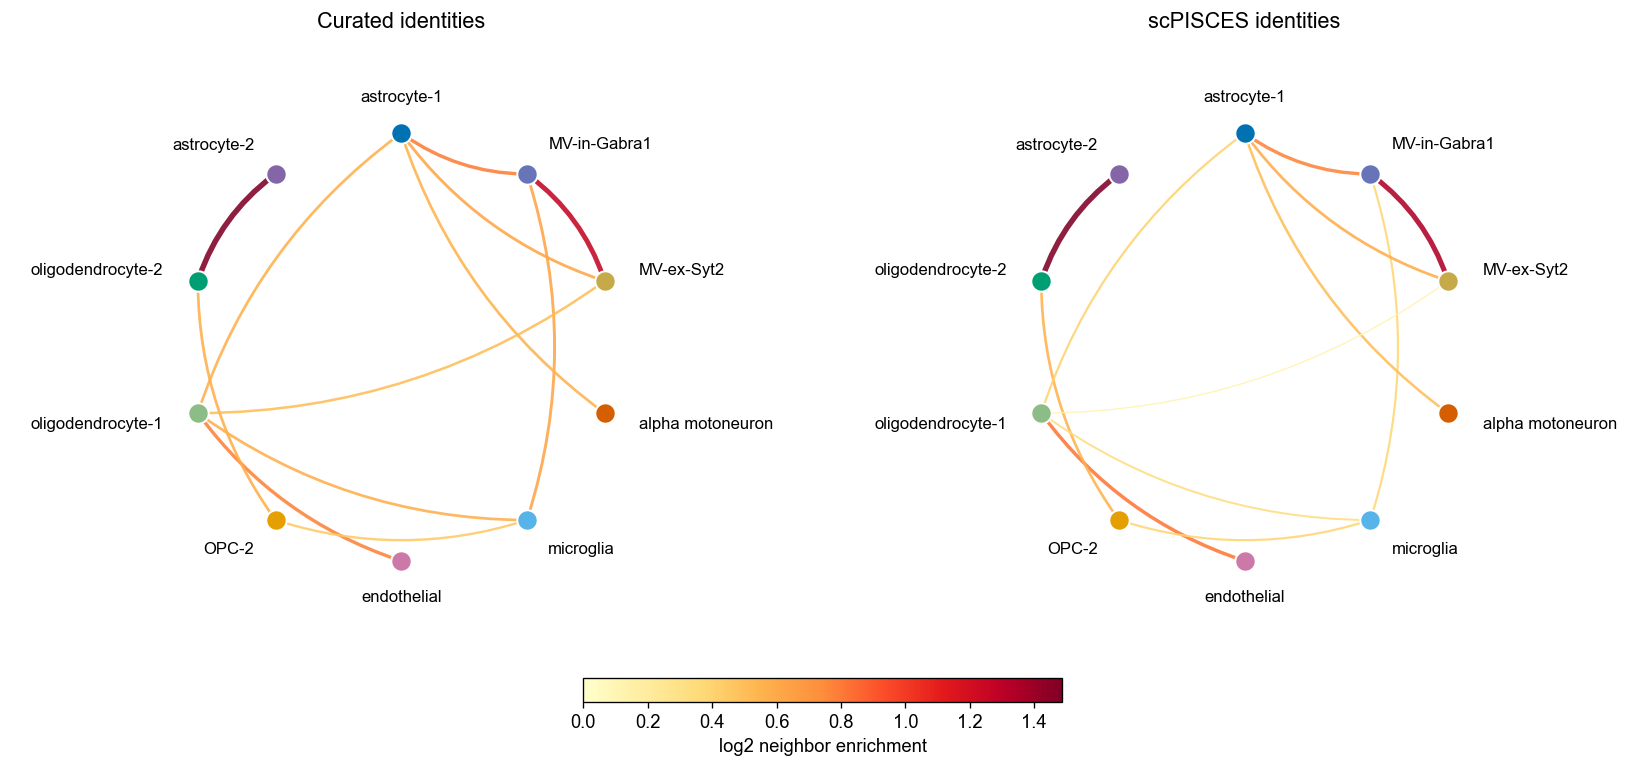

In [5]:
from matplotlib.patches import FancyArrowPatch
from matplotlib.cm import ScalarMappable

edges = pairs.loc[pairs.curated.gt(0)].nlargest(12, "curated")
node_colors = dict(zip(selected_types,
    ["#0072B2", "#8466a8", "#009E73", "#8dbd86", "#E69F00", "#CC79A7",
     "#56B4E9", "#D55E00", "#c6aa4a", "#6874b8"]))
angles = np.linspace(np.pi/2, np.pi/2 + 2*np.pi, len(selected_types), endpoint=False)
positions = {name: np.array([np.cos(t), np.sin(t)]) for name,t in zip(selected_types, angles)}
maximum = max(edges[["curated", "predicted"]].to_numpy().max(), 0.1)
scale = Normalize(0, maximum)
cmap = plt.get_cmap("YlOrRd")
fig, axes = plt.subplots(1, 2, figsize=(14, 6.3), layout="constrained")
for ax, column, title in zip(axes, ["curated", "predicted"], ["Curated identities", "scPISCES identities"]):
    for edge in edges.itertuples():
        value = getattr(edge, column)
        patch = FancyArrowPatch(positions[edge.type_a], positions[edge.type_b],
                arrowstyle="-", connectionstyle="arc3,rad=0.16",
                linewidth=0.6 + 2.7 * max(value, 0)/maximum,
                color=cmap(scale(value)) if value > 0 else "#c3c9ce",
                linestyle="-" if value > 0 else "--", alpha=0.88, zorder=1)
        ax.add_patch(patch)
    for name, xy in positions.items():
        ax.scatter(*xy, s=150, color=node_colors[name], edgecolors="white", linewidths=1.2, zorder=3)
        label = "OPC-2" if name == "oligodendrocyte progenitor-2" else textwrap.fill(name, 17)
        x, y = 1.17 * xy
        ax.text(x, y, label, ha="center" if abs(x)<0.1 else ("left" if x>0 else "right"),
                va="center", fontsize=10, bbox={"facecolor":"white", "edgecolor":"none", "pad":0.5})
    ax.set_title(title, pad=12)
    ax.set_xlim(-1.82, 1.82)
    ax.set_ylim(-1.4, 1.4)
    clean_map(ax)
fig.colorbar(ScalarMappable(norm=scale, cmap=cmap), ax=axes, orientation="horizontal",
             shrink=0.35, fraction=0.04, pad=0.05, label="log2 neighbor enrichment")
save_figure(fig, OUTPUT, "merfish_spatial_neighborhood_networks")
plt.show()

Spatial coordinates define these neighborhoods only for visualization and analysis. scPISCES cell identities in this example are predicted from expression profiles.